# LoRA Rank Comparison: CIFAR-10 + ViT/DeiT-style model

**Goal:** Compare LoRA ranks `16` and `32` (Notebook 1). For Notebook 2, change `RANKS = [64, 128]`.

We record training/validation loss and accuracy each epoch. A growing training–validation gap plus worsening validation loss can indicate overfitting.

**Runtime note:** Run the notebook from top to bottom. If you change installed packages, restart the Kaggle runtime first.


In [1]:
# Cell 1 (New) — Uninstall torchao to fix PEFT compatibility
!pip uninstall -y torchao

Found existing installation: torchao 0.10.0
Uninstalling torchao-0.10.0:
  Successfully uninstalled torchao-0.10.0


In [2]:
# Cell 2 — Imports and experiment settings (CIFAR-10 PATH B)
import os
import random
import gc
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn

from torch.utils.data import DataLoader, random_split, Subset, ConcatDataset
from torchvision.datasets import CIFAR10, ImageFolder
from torchvision import transforms
from transformers import AutoImageProcessor, AutoModelForImageClassification
from peft import LoraConfig, get_peft_model
from tqdm.auto import tqdm
from IPython.display import display

# =========================================================
# Reproducibility
# =========================================================
SEED = 42

# =========================================================
# Model
# =========================================================
MODEL_NAME = "facebook/deit-small-patch16-224"

# =========================================================
# Experiment settings — PATH B: CIFAR-10 with small train set
RANKS = [8, 16, 32, 64, 128, 256]
EPOCHS = 15              # overfitting দেখার জন্য 12 (आवश्यक হলে বাড়াও)

BATCH_SIZE = 32
LEARNING_RATE = 2e-4
MAX_TRAIN = 2_000        # 10-class CIFAR-10 — 2000 sample = overfit window
MAX_VAL   = 500          # val বড় = reliable generalization estimate
NUM_WORKERS = 0

# =========================================================
# Dataset switch — CIFAR-10 (PATH B)
# =========================================================
USE_MOON_DATASET = False
DATA_ROOT = "/kaggle/input/datasets/bhargavlc/lunar-craters-and-boulders"  # unused

# =========================================================
# Device
# =========================================================
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

# =========================================================
# Seed helper
# =========================================================
def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
        torch.backends.cudnn.deterministic = True
        torch.backends.cudnn.benchmark = False

set_seed()

# =========================================================
# Sanity: DATA_ROOT exists? (শুধু moon-এর জন্য)
# =========================================================
if USE_MOON_DATASET:
    if os.path.isdir(DATA_ROOT):
        print("DATA_ROOT OK:", DATA_ROOT)
        print("Subfolders:", sorted(os.listdir(DATA_ROOT))[:10])
    else:
        print("⚠️ DATA_ROOT not found:", DATA_ROOT)
else:
    print("Dataset: CIFAR-10 (will auto-download to ./data)")
    print("Note: Internet must be ON for download")

Device: cuda
Dataset: CIFAR-10 (will auto-download to ./data)
Note: Internet must be ON for download


In [3]:
# Cell 3 — Load Moon ImageFolder + adaptive split
processor = AutoImageProcessor.from_pretrained(MODEL_NAME)

def _get_size(p):
    sz = p.size
    if isinstance(sz, dict):
        return sz.get("height", 224)
    if hasattr(sz, "height"):
        return sz.height
    return 224

image_size = _get_size(processor)
image_mean = getattr(processor, "image_mean", [0.485, 0.456, 0.406])
image_std  = getattr(processor, "image_std",  [0.229, 0.224, 0.225])

transform = transforms.Compose([
    transforms.Resize((image_size, image_size)),
    transforms.ToTensor(),
    transforms.Normalize(mean=image_mean, std=image_std),
])

if USE_MOON_DATASET:
    # path auto-correct: user path → lunar_dataset/ subfolder
    real_root = DATA_ROOT
    if not os.path.isdir(real_root):
        raise FileNotFoundError(f"DATA_ROOT missing: {real_root}")
    # যদি এক level নিচে 'lunar_dataset' থাকে
    sub = os.path.join(real_root, "lunar_dataset")
    if os.path.isdir(sub):
        real_root = sub
    full_train_dataset = ImageFolder(root=real_root, transform=transform)
else:
    full_train_dataset = CIFAR10(root="./data", train=True, download=True, transform=transform)

class_names = full_train_dataset.classes
num_classes = len(class_names)

n_total = len(full_train_dataset)
n_val = min(MAX_VAL, max(50, int(0.2 * n_total)))
n_train_pool = n_total - n_val

train_pool, val_pool = random_split(
    full_train_dataset,
    [n_train_pool, n_val],
    generator=torch.Generator().manual_seed(SEED)
)

train_subset = Subset(train_pool, range(min(MAX_TRAIN, len(train_pool))))
val_subset   = Subset(val_pool,   range(min(MAX_VAL,   len(val_pool))))

print("Dataset:", "Moon (ImageFolder)" if USE_MOON_DATASET else "CIFAR-10")
print("Classes:", class_names)
print("Training samples:", len(train_subset))
print("Validation samples:", len(val_subset))
print("Image size:", image_size)

preprocessor_config.json:   0%|          | 0.00/160 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/69.6k [00:00<?, ?B/s]

100%|██████████| 170M/170M [10:50<00:00, 262kB/s] 


Dataset: CIFAR-10
Classes: ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']
Training samples: 2000
Validation samples: 500
Image size: 224


In [4]:
# Cell 4 — Training and evaluation function
def train_one_rank(rank):
    # Reset seed so each rank starts from a comparable setup
    set_seed(SEED)

    print(f"\\n{'=' * 18} LoRA rank={rank} {'=' * 18}")

    model = AutoModelForImageClassification.from_pretrained(
        MODEL_NAME,
        num_labels=len(class_names),
        ignore_mismatched_sizes=True
    )

    # This checkpoint exposes attention layers named q_proj and v_proj.
    # Leave task_type unset for this image-classification model.
    lora_config = LoraConfig(
        r=rank,
        lora_alpha=rank,
        target_modules=["q_proj", "v_proj"],
        lora_dropout=0.1,
        bias="none",
        modules_to_save=["classifier"]
    )

    model = get_peft_model(model, lora_config)
    model.print_trainable_parameters()
    model.to(device)

    # Same data order seed for a fairer rank comparison
    train_generator = torch.Generator().manual_seed(SEED)
    train_loader = DataLoader(
        train_subset,
        batch_size=BATCH_SIZE,
        shuffle=True,
        generator=train_generator,
        num_workers=NUM_WORKERS,
        pin_memory=(device.type == "cuda")
    )
    val_loader = DataLoader(
        val_subset,
        batch_size=BATCH_SIZE,
        shuffle=False,
        num_workers=NUM_WORKERS,
        pin_memory=(device.type == "cuda")
    )

    optimizer = torch.optim.AdamW(
        [p for p in model.parameters() if p.requires_grad],
        lr=LEARNING_RATE
    )
    criterion = nn.CrossEntropyLoss()
    history = []

    for epoch in range(EPOCHS):
        # Training
        model.train()
        train_loss_sum, train_correct, train_total = 0.0, 0, 0

        for images, labels in tqdm(
            train_loader,
            desc=f"Rank {rank} | Train {epoch + 1}/{EPOCHS}"
        ):
            images = images.to(device, non_blocking=True)
            labels = labels.to(device, non_blocking=True)

            optimizer.zero_grad(set_to_none=True)
            logits = model(pixel_values=images).logits
            loss = criterion(logits, labels)
            loss.backward()
            optimizer.step()

            n = labels.size(0)
            train_loss_sum += loss.item() * n
            train_correct += (logits.argmax(dim=1) == labels).sum().item()
            train_total += n

        train_loss = train_loss_sum / train_total
        train_accuracy = train_correct / train_total

        # Validation
        model.eval()
        val_loss_sum, val_correct, val_total = 0.0, 0, 0

        with torch.no_grad():
            for images, labels in tqdm(
                val_loader,
                desc=f"Rank {rank} | Valid {epoch + 1}/{EPOCHS}",
                leave=False
            ):
                images = images.to(device, non_blocking=True)
                labels = labels.to(device, non_blocking=True)

                logits = model(pixel_values=images).logits
                loss = criterion(logits, labels)

                n = labels.size(0)
                val_loss_sum += loss.item() * n
                val_correct += (logits.argmax(dim=1) == labels).sum().item()
                val_total += n

        val_loss = val_loss_sum / val_total
        val_accuracy = val_correct / val_total

        row = {
            "rank": rank,
            "epoch": epoch + 1,
            "train_loss": train_loss,
            "train_accuracy": train_accuracy,
            "val_loss": val_loss,
            "val_accuracy": val_accuracy,
            "train_val_gap": train_accuracy - val_accuracy
        }
        history.append(row)

        print(
            f"Rank={rank} | Epoch={epoch + 1}/{EPOCHS} | "
            f"train_loss={train_loss:.4f} | train_acc={train_accuracy:.4f} | "
            f"val_loss={val_loss:.4f} | val_acc={val_accuracy:.4f} | "
            f"gap={train_accuracy - val_accuracy:.4f}"
        )

    save_path = f"lora_deit_rank_{rank}"
    model.save_pretrained(save_path)
    print("Saved adapter:", save_path)

    del model, optimizer, train_loader, val_loader
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

    return history


In [5]:
# Cell 5 — Train each requested rank and save results
all_history = []

for rank in RANKS:
    rank_history = train_one_rank(rank)
    all_history.extend(rank_history)

results = pd.DataFrame(all_history)
csv_name = f"rank_{'_vs_'.join(map(str, RANKS))}_results.csv"
results.to_csv(csv_name, index=False)

print("Saved results to:", csv_name)
display(results)


\n================== LoRA rank=8 ==================


[transformers] You passed `num_labels=10` which is incompatible to the `id2label` map of length `1000`.


pytorch_model.bin: reconstructing file:   0%|          |  0.00B / 88.3MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/200 [00:00<?, ?it/s]

[transformers] ViTForImageClassification LOAD REPORT from: facebook/deit-small-patch16-224
Key               | Status   |                                                                                           
------------------+----------+-------------------------------------------------------------------------------------------
classifier.bias   | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([1000]) vs model:torch.Size([10])          
classifier.weight | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([1000, 384]) vs model:torch.Size([10, 384])

Notes:
- MISMATCH:	ckpt weights were loaded, but they did not match the original empty weight shapes.


... (295 outputs left out)

Rank 256 | Train 15/15:   0%|          | 0/63 [00:00<?, ?it/s]

Rank 256 | Valid 15/15:   0%|          | 0/16 [00:00<?, ?it/s]

Rank=256 | Epoch=15/15 | train_loss=0.0007 | train_acc=1.0000 | val_loss=0.1711 | val_acc=0.9480 | gap=0.0520
Saved adapter: lora_deit_rank_256
Saved results to: rank_8_vs_16_vs_32_vs_64_vs_128_vs_256_results.csv


,rank,epoch,train_loss,train_accuracy,val_loss,val_accuracy,train_val_gap
0,8,1,1.865073,0.4585,1.248143,0.782,-0.3235
1,8,2,0.752242,0.8775,0.467664,0.910,-0.0325
2,8,3,0.321856,0.9295,0.298729,0.924,0.0055
3,8,4,0.206384,0.9520,0.239520,0.932,0.0200
4,8,5,0.139667,0.9670,0.214699,0.936,0.0310
...,...,...,...,...,...,...,...
85,256,11,0.001223,1.0000,0.159664,0.950,0.0500
86,256,12,0.001071,1.0000,0.163575,0.950,0.0500
87,256,13,0.000927,1.0000,0.165568,0.950,0.0500
88,256,14,0.000828,1.0000,0.168424,0.950,0.0500


In [6]:
# Cell 6 — Best-metrics per rank (overfit-onset detection)
best_per_rank = []
for rank in RANKS:
    df = results[results["rank"] == rank].sort_values("epoch").reset_index(drop=True)
    
    # Best epoch for val_loss (lowest = best generalization point)
    best_vloss_idx = df["val_loss"].idxmin()
    best_vloss_row = df.loc[best_vloss_idx]
    
    # Best epoch for val_accuracy (highest)
    best_vacc_idx = df["val_accuracy"].idxmax()
    best_vacc_row = df.loc[best_vacc_idx]
    
    # Final epoch
    final_row = df.iloc[-1]
    
    best_per_rank.append({
        "rank": int(rank),
        "best_val_acc":        best_vacc_row["val_accuracy"],
        "best_val_acc_epoch":  int(best_vacc_row["epoch"]),
        "best_val_loss":       best_vloss_row["val_loss"],
        "best_val_loss_epoch": int(best_vloss_row["epoch"]),
        "final_val_acc":       final_row["val_accuracy"],
        "final_val_loss":      final_row["val_loss"],
        "final_train_acc":     final_row["train_accuracy"],
        "final_train_loss":    final_row["train_loss"],
        "overfit_gap":         final_row["train_accuracy"] - final_row["val_accuracy"],
        "degradation":         best_vacc_row["val_accuracy"] - final_row["val_accuracy"],
    })

best_df = pd.DataFrame(best_per_rank).sort_values("rank").reset_index(drop=True)

# Params for each rank
def count_adapter_params(rank):
    import os
    for fname in ("adapter_model.safetensors", "adapter_model.bin"):
        path = f"lora_deit_rank_{rank}/{fname}"
        if not os.path.exists(path): continue
        try:
            if fname.endswith(".safetensors"):
                from safetensors.torch import load_file
                sd = load_file(path)
            else:
                sd = torch.load(path, map_location="cpu")
            return int(sum(v.numel() for v in sd.values()))
        except Exception:
            return None
    return None

best_df["n_params"] = best_df["rank"].apply(count_adapter_params)

print("=" * 108)
print("  BEST-METRICS TABLE — per rank (overfit onset analysis)")
print("=" * 108)
print(f"{'Rank':<6}{'BestVAcc':>10}{'@Ep':>5}{'BestVLoss':>11}{'@Ep':>5}"
      f"{'FinalVAcc':>11}{'FinalVLoss':>12}{'Gap':>9}{'Degrad':>9}{'Params':>12}")
print("-" * 108)
for _, row in best_df.iterrows():
    print(f"{row['rank']:<6}{row['best_val_acc']:>10.4f}{row['best_val_acc_epoch']:>5}"
          f"{row['best_val_loss']:>11.4f}{row['best_val_loss_epoch']:>5}"
          f"{row['final_val_acc']:>11.4f}{row['final_val_loss']:>12.4f}"
          f"{row['overfit_gap']:>+9.4f}{row['degradation']:>+9.4f}{row['n_params']:>12,}")
print("=" * 108)
print()
print("Column meanings:")
print("  BestVAcc @Ep      = highest val_accuracy & the epoch it occurred (best generalization point)")
print("  BestVLoss @Ep     = lowest val_loss & its epoch (typically = when overfitting begins)")
print("  FinalVAcc/VLoss   = last epoch (epoch 15) metrics — after overfit has progressed")
print("  Gap               = train_acc − val_acc at final epoch (bigger = more overfit)")
print("  Degrad            = BestVAcc − FinalVAcc (positive = overfitting is actively hurting)")

# Sweet spot detector
print("\n" + "=" * 108)
print("  SWEET-SPOT DETECTOR")
print("=" * 108)

max_val_acc = best_df["best_val_acc"].max()
print(f"  Best val_acc overall: {max_val_acc*100:.2f}% (rank {best_df.loc[best_df['best_val_acc'].idxmax(), 'rank']})")

threshold = max_val_acc - 0.005   # within 0.5% of best
candidates = best_df[best_df["best_val_acc"] >= threshold]
if len(candidates) > 0:
    sweet_rank = int(candidates["rank"].min())
    sweet_row  = candidates[candidates["rank"] == sweet_rank].iloc[0]
    print(f"  Smallest rank within 0.5% of best: Rank {sweet_rank}")
    print(f"    - best val_acc = {sweet_row['best_val_acc']*100:.2f}%")
    print(f"    - gap          = {sweet_row['overfit_gap']:+.4f}")
    print(f"    - params       = {sweet_row['n_params']:,}")

# Overfit onset rank
print("\n  Overfit onset (rank where gap crosses 5%):")
over5 = best_df[best_df["overfit_gap"] > 0.05]
if len(over5) > 0:
    onset = int(over5["rank"].min())
    print(f"    → First rank with gap > 5% = Rank {onset}")
    print(f"    → Ranks < {onset} are (mostly) safe; ranks ≥ {onset} are overfitting")
else:
    print(f"    → No rank exceeds 5% gap within {EPOCHS} epochs — dataset is still learnable")

display(best_df)

  BEST-METRICS TABLE — per rank (overfit onset analysis)
Rank    BestVAcc  @Ep  BestVLoss  @Ep  FinalVAcc  FinalVLoss      Gap   Degrad      Params
------------------------------------------------------------------------------------------------------------
8.0       0.9520 12.0     0.1626 10.0     0.9500      0.1680  +0.0500  +0.0020   151,306.0
16.0      0.9500 13.0     0.1603  9.0     0.9400      0.1846  +0.0600  +0.0100   298,762.0
32.0      0.9480 14.0     0.1540  9.0     0.9460      0.1758  +0.0540  +0.0020   593,674.0
64.0      0.9520  4.0     0.1601  6.0     0.9420      0.1901  +0.0580  +0.0100 1,183,498.0
128.0     0.9540  6.0     0.1586  6.0     0.9420      0.2015  +0.0580  +0.0120 2,363,146.0
256.0     0.9520  6.0     0.1427  6.0     0.9480      0.1711  +0.0520  +0.0040 4,722,442.0

Column meanings:
  BestVAcc @Ep      = highest val_accuracy & the epoch it occurred (best generalization point)
  BestVLoss @Ep     = lowest val_loss & its epoch (typically = when overfitting begi

,rank,best_val_acc,best_val_acc_epoch,best_val_loss,best_val_loss_epoch,final_val_acc,final_val_loss,final_train_acc,final_train_loss,overfit_gap,degradation,n_params
0,8,0.952,12,0.162587,10,0.950,0.168044,1.0,0.006085,0.050,0.002,151306
1,16,0.950,13,0.160319,9,0.940,0.184561,1.0,0.002970,0.060,0.010,298762
2,32,0.948,14,0.154005,9,0.946,0.175778,1.0,0.001909,0.054,0.002,593674
3,64,0.952,4,0.160087,6,0.942,0.190087,1.0,0.001330,0.058,0.010,1183498
4,128,0.954,6,0.158630,6,0.942,0.201495,1.0,0.000956,0.058,0.012,2363146
5,256,0.952,6,0.142665,6,0.948,0.171136,1.0,0.000732,0.052,0.004,4722442


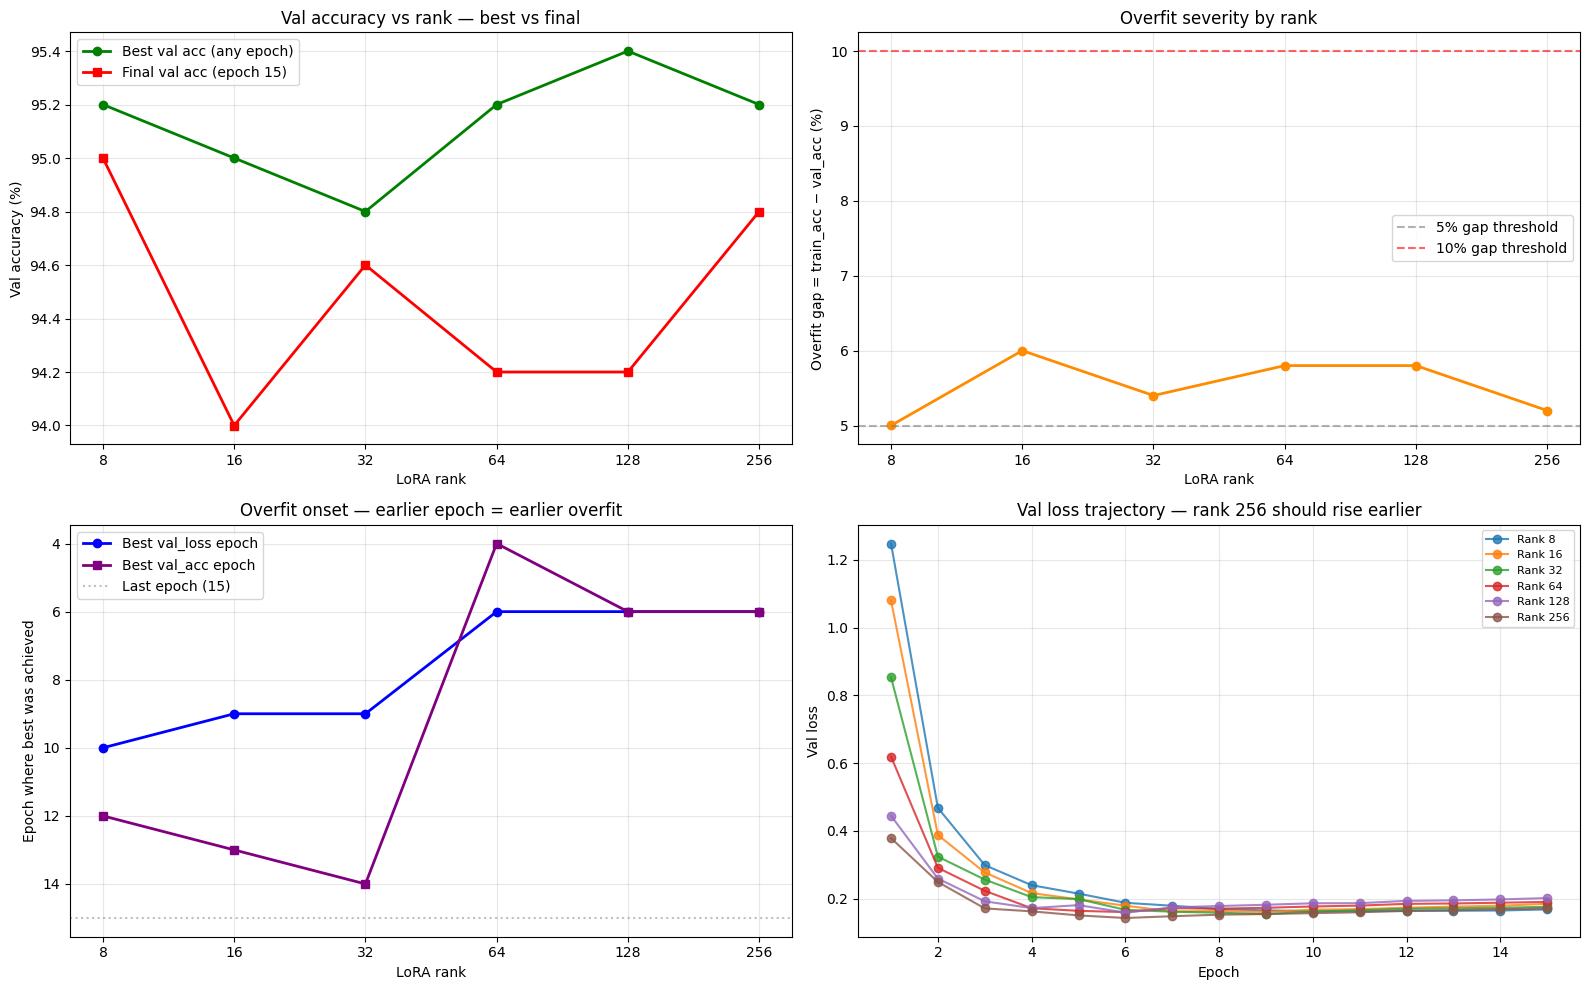

In [7]:
# Cell 7 — Cross-rank visualization
fig, axes = plt.subplots(2, 2, figsize=(16, 10))

# ----- Panel 1: Best vs Final val accuracy across ranks -----
ax = axes[0, 0]
ax.plot(best_df["rank"], best_df["best_val_acc"] * 100, marker="o", 
        label="Best val acc (any epoch)", color="green", linewidth=2)
ax.plot(best_df["rank"], best_df["final_val_acc"] * 100, marker="s", 
        label="Final val acc (epoch 15)", color="red", linewidth=2)
ax.set_xlabel("LoRA rank")
ax.set_ylabel("Val accuracy (%)")
ax.set_title("Val accuracy vs rank — best vs final")
ax.set_xscale("log", base=2)
ax.set_xticks(best_df["rank"])
ax.set_xticklabels(best_df["rank"])
ax.legend()
ax.grid(True, alpha=0.3)

# ----- Panel 2: Overfit gap across ranks -----
ax = axes[0, 1]
ax.plot(best_df["rank"], best_df["overfit_gap"] * 100, marker="o", 
        color="darkorange", linewidth=2)
ax.axhline(y=5, linestyle="--", color="gray", alpha=0.6, label="5% gap threshold")
ax.axhline(y=10, linestyle="--", color="red", alpha=0.6, label="10% gap threshold")
ax.set_xlabel("LoRA rank")
ax.set_ylabel("Overfit gap = train_acc − val_acc (%)")
ax.set_title("Overfit severity by rank")
ax.set_xscale("log", base=2)
ax.set_xticks(best_df["rank"])
ax.set_xticklabels(best_df["rank"])
ax.legend()
ax.grid(True, alpha=0.3)

# ----- Panel 3: Overfit onset epoch per rank -----
ax = axes[1, 0]
ax.plot(best_df["rank"], best_df["best_val_loss_epoch"], marker="o", 
        label="Best val_loss epoch", color="blue", linewidth=2)
ax.plot(best_df["rank"], best_df["best_val_acc_epoch"], marker="s", 
        label="Best val_acc epoch", color="purple", linewidth=2)
ax.axhline(y=EPOCHS, linestyle=":", color="gray", alpha=0.5, 
           label=f"Last epoch ({EPOCHS})")
ax.set_xlabel("LoRA rank")
ax.set_ylabel("Epoch where best was achieved")
ax.set_title("Overfit onset — earlier epoch = earlier overfit")
ax.set_xscale("log", base=2)
ax.set_xticks(best_df["rank"])
ax.set_xticklabels(best_df["rank"])
ax.legend()
ax.grid(True, alpha=0.3)
ax.invert_yaxis()  # lower epoch = higher on plot = worse

# ----- Panel 4: Val-loss curves for all ranks -----
ax = axes[1, 1]
for rank in RANKS:
    df = results[results["rank"] == rank].sort_values("epoch")
    ax.plot(df["epoch"], df["val_loss"], marker="o", 
            label=f"Rank {rank}", alpha=0.8)
ax.set_xlabel("Epoch")
ax.set_ylabel("Val loss")
ax.set_title("Val loss trajectory — rank 256 should rise earlier")
ax.legend(fontsize=8)
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [8]:
# Cell 8 — Multi-rank verdict (which rank to use?)
print("=" * 108)
print("  MULTI-RANK VERDICT")
print("=" * 108)

# Sort by best_val_acc descending
ranked = best_df.sort_values("best_val_acc", ascending=False).reset_index(drop=True)
max_acc = ranked.iloc[0]["best_val_acc"]
max_rank = int(ranked.iloc[0]["rank"])

print(f"\n  1. Highest val accuracy: Rank {max_rank} ({max_acc*100:.2f}%)")
print(f"     Params: {ranked.iloc[0]['n_params']:,}")
print(f"     Gap   : {ranked.iloc[0]['overfit_gap']*100:+.2f}%")

print(f"\n  2. Lowest overfit gap:")
lowest_gap_row = best_df.loc[best_df["overfit_gap"].idxmin()]
print(f"     Rank {int(lowest_gap_row['rank'])} — gap = {lowest_gap_row['overfit_gap']*100:+.2f}%")
print(f"     Its val_acc = {lowest_gap_row['best_val_acc']*100:.2f}%")

print(f"\n  3. Efficiency-optimal (smallest rank within 0.5% of best):")
if len(candidates) > 0:
    print(f"     Rank {sweet_rank} — {sweet_row['n_params']:,} params, "
          f"val_acc {sweet_row['best_val_acc']*100:.2f}%")

print(f"\n  4. Overfit onset (gap > 5%):")
if len(over5) > 0:
    print(f"     Starts at Rank {int(over5['rank'].min())}")
else:
    print(f"     No rank exceeded 5% in {EPOCHS} epochs")

print("\n" + "=" * 108)
print("  RECOMMENDATION")
print("=" * 108)
print(f"""
  Based on the sweep:
  • Up to rank {sweet_rank if len(candidates) > 0 else max_rank}, val accuracy improves/stays 
    with increasing rank. Above that, gain saturates.
  • Ranks ≥ {int(over5['rank'].min()) if len(over5) > 0 else 'N/A'} show noticeable overfit 
    (gap > 5%) — the model memorizes the 2000 training samples.
  • Sweet spot = Rank {sweet_rank if len(candidates) > 0 else max_rank}:
    highest val accuracy within 0.5% of best, using minimum parameters.
""")
print("=" * 108)

  MULTI-RANK VERDICT

  1. Highest val accuracy: Rank 128 (95.40%)
     Params: 2,363,146.0
     Gap   : +5.80%

  2. Lowest overfit gap:
     Rank 8 — gap = +5.00%
     Its val_acc = 95.20%

  3. Efficiency-optimal (smallest rank within 0.5% of best):
     Rank 8 — 151,306.0 params, val_acc 95.20%

  4. Overfit onset (gap > 5%):
     Starts at Rank 8

  RECOMMENDATION

  Based on the sweep:
  • Up to rank 8, val accuracy improves/stays 
    with increasing rank. Above that, gain saturates.
  • Ranks ≥ 8 show noticeable overfit 
    (gap > 5%) — the model memorizes the 2000 training samples.
  • Sweet spot = Rank 8:
    highest val accuracy within 0.5% of best, using minimum parameters.



In [9]:
# Cell 9 — Full evaluation: Rank 16 vs 32 on TRAIN / VAL / ALL 230 (path-safe)

import time, gc, torch
import numpy as np
import pandas as pd
from peft import PeftModel
from sklearn.metrics import (
    accuracy_score, precision_recall_fscore_support,
    confusion_matrix, roc_auc_score
)

# ---------- helpers ----------
def load_adapter(rank):
    base = AutoModelForImageClassification.from_pretrained(
        MODEL_NAME, num_labels=num_classes, ignore_mismatched_sizes=True
    )
    m = PeftModel.from_pretrained(base, f"lora_deit_rank_{rank}")
    m.eval().to(device)
    return m

def run_inference(model, loader):
    preds, labels, probs = [], [], []
    t0 = time.time()
    with torch.no_grad():
        for imgs, lbls in loader:
            imgs = imgs.to(device)
            logits = model(pixel_values=imgs).logits
            preds.append(logits.argmax(-1).cpu())
            labels.append(lbls)
            probs.append(torch.softmax(logits, -1).cpu())
    if device.type == "cuda":
        torch.cuda.synchronize()
    dt = time.time() - t0
    return (torch.cat(preds).numpy(),
            torch.cat(labels).numpy(),
            torch.cat(probs).numpy(), dt)

def calc_metrics(preds, labels, probs, dt):
    acc = accuracy_score(labels, preds)
    p, r, f1, _ = precision_recall_fscore_support(
        labels, preds, average=None, zero_division=0,
        labels=list(range(num_classes)))
    cm = confusion_matrix(labels, preds, labels=list(range(num_classes)))
    auc = None
    if probs.shape[1] == 2 and len(set(labels)) > 1:
        try: auc = float(roc_auc_score(labels, probs[:, 1]))
        except Exception: pass
    return dict(
        acc=acc, f1=f1, macro_f1=float(f1.mean()),
        p=p, r=r, cm=cm, auc=auc,
        conf=float(probs.max(1).mean()),
        n=len(labels),
        ms=dt / max(len(labels), 1) * 1000,
    )

# ---------- three splits ----------
# CIFAR-10-এ full_train_dataset = 50,000। "ALL" অর্থহীন,
# তাই train+val = 2500 দেখাই combined হিসেবে।
combined_used = ConcatDataset([train_subset, val_subset])

split_defs = [
    ("train (seen)",     train_subset,   len(train_subset)),      # 2000
    ("val (held-out)",   val_subset,     len(val_subset)),        # 500
    ("train+val (used)", combined_used,  len(combined_used)),     # 2500
]

# all splits-এর নাম এক জায়গায় রাখো → নিচে dynamic reference
SPLIT_NAMES = [s[0] for s in split_defs]
PRIMARY_SPLIT = SPLIT_NAMES[-1]   # "train+val (used)" — combined দেখার জন্য
HONEST_SPLIT  = SPLIT_NAMES[1]    # "val (held-out)" — honest generalization

def make_loader(subset):
    return DataLoader(subset, batch_size=BATCH_SIZE, shuffle=False,
                      num_workers=0, pin_memory=(device.type == "cuda"))

# ---------- run ----------
all_reports = {r: {} for r in RANKS}
for rank in RANKS:
    print(f"\nLoading & evaluating Rank {rank}...")
    model = load_adapter(rank)
    for name, subset, n in split_defs:
        preds, labels, probs, dt = run_inference(model, make_loader(subset))
        all_reports[rank][name] = calc_metrics(preds, labels, probs, dt)
    del model; gc.collect()
    if device.type == "cuda": torch.cuda.empty_cache()
    print(f"  Rank {rank} done ✅")

# ---------- summary table ----------
print("\n" + "=" * 88)
print("  PERFORMANCE SUMMARY")
print("=" * 88)
print(f"{'Rank':<6}{'Split':<20}{'N':>6}{'Acc':>8}{'MacroF1':>10}"
      f"{'AUC':>9}{'Conf':>8}{'ms/img':>9}")
print("-" * 88)
for rank in RANKS:
    for name, _, n in split_defs:
        m = all_reports[rank][name]
        auc_s = f"{m['auc']:.4f}" if m['auc'] is not None else "  —   "
        print(f"{rank:<6}{name:<20}{m['n']:>6}{m['acc']:>8.4f}"
              f"{m['macro_f1']:>10.4f}{auc_s:>9}{m['conf']:>8.4f}"
              f"{m['ms']:>9.2f}")
    print("-" * 88)

# ---------- per-class on PRIMARY split ----------
print("\n" + "=" * 88)
print(f"  PER-CLASS BREAKDOWN — {PRIMARY_SPLIT}")
print("=" * 88)
for rank in RANKS:
    m = all_reports[rank][PRIMARY_SPLIT]
    print(f"\nRank {rank}:")
    print(f"  {'class':<12}{'precision':>12}{'recall':>10}{'f1':>10}{'support':>10}")
    for i, cname in enumerate(class_names):
        sup = int(m["cm"][i].sum())
        print(f"  {cname:<12}{m['p'][i]:>12.3f}{m['r'][i]:>10.3f}"
              f"{m['f1'][i]:>10.3f}{sup:>10}")

# ---------- confusion matrices ----------
print("\n" + "=" * 88)
print(f"  CONFUSION MATRIX — {PRIMARY_SPLIT} (rows=true, cols=pred)")
print("=" * 88)
for rank in RANKS:
    m = all_reports[rank][PRIMARY_SPLIT]
    df = pd.DataFrame(m["cm"],
        index=[f"true_{c}" for c in class_names],
        columns=[f"pred_{c}" for c in class_names])
    print(f"\nRank {rank}:")
    print(df)

# ---------- overfit gap ----------
print("\n" + "=" * 88)
print(f"  OVERFIT GAP ({HONEST_SPLIT}) — smaller = better generalization")
print("=" * 88)
for rank in RANKS:
    tr = all_reports[rank][SPLIT_NAMES[0]]["acc"]
    va = all_reports[rank][HONEST_SPLIT]["acc"]
    gap = tr - va
    if gap > 0.10:   flag = "⚠️ strong overfit"
    elif gap > 0.05: flag = "🟡 mild overfit"
    else:            flag = "✅ good"
    print(f"  Rank {rank:>3}: train={tr:.4f}  val={va:.4f}  gap={gap:+.4f}  {flag}")

# ---------- verdict ----------
print("\n" + "=" * 88)
print("  FINAL VERDICT")
print("=" * 88)
rA, rB = RANKS[0], RANKS[1]
mA = all_reports[rA][PRIMARY_SPLIT]
mB = all_reports[rB][PRIMARY_SPLIT]

acc_tie = abs(mA['acc'] - mB['acc']) < 1e-6
f1_tie  = abs(mA['macro_f1'] - mB['macro_f1']) < 1e-6

if acc_tie and f1_tie:
    winner = min(rA, rB)
    reason = "identical accuracy & macro-F1 — smaller rank wins on efficiency"
elif mA['macro_f1'] >= mB['macro_f1']:
    winner, reason = rA, "higher macro-F1"
else:
    winner, reason = rB, "higher macro-F1"

print(f"  Acc       : {'TIE' if acc_tie else ('Rank '+str(rA if mA['acc']>mB['acc'] else rB)+' wins')}")
print(f"  Macro-F1  : {'TIE' if f1_tie else ('Rank '+str(rA if mA['macro_f1']>mB['macro_f1'] else rB)+' wins')}")
print(f"  Params    : Rank {min(rA,rB)} (fewer)")

# overfit comparison on honest split
gapA = all_reports[rA][SPLIT_NAMES[0]]["acc"] - all_reports[rA][HONEST_SPLIT]["acc"]
gapB = all_reports[rB][SPLIT_NAMES[0]]["acc"] - all_reports[rB][HONEST_SPLIT]["acc"]
less_overfit = rA if gapA < gapB else rB
print(f"  Overfit gap: Rank {rA}={gapA:+.4f}  |  Rank {rB}={gapB:+.4f}  → Rank {less_overfit} overfits less")

print(f"\n  🏆 ACCURACY WINNER: Rank {winner}")
print(f"  Reason  : {reason}")
print(f"  🎯 GENERALIZATION WINNER (less overfit): Rank {less_overfit}")
print("=" * 88)

print("\n⚠️  Honesty note:")
print(f"  'train (seen)' = {len(train_subset)} samples used in training → optimistic.")
print(f"  'val (held-out)' = {len(val_subset)} samples → honest generalization metric.")
print(f"  'train+val (used)' = both combined → sanity check only.")
print(f"  With N={len(val_subset)}, one wrong prediction = {100/len(val_subset):.1f}% accuracy change.")

[transformers] You passed `num_labels=10` which is incompatible to the `id2label` map of length `1000`.



Loading & evaluating Rank 8...


Loading weights:   0%|          | 0/200 [00:00<?, ?it/s]

[transformers] ViTForImageClassification LOAD REPORT from: facebook/deit-small-patch16-224
Key               | Status   |                                                                                           
------------------+----------+-------------------------------------------------------------------------------------------
classifier.bias   | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([1000]) vs model:torch.Size([10])          
classifier.weight | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([1000, 384]) vs model:torch.Size([10, 384])

Notes:
- MISMATCH:	ckpt weights were loaded, but they did not match the original empty weight shapes.
[transformers] You passed `num_labels=10` which is incompatible to the `id2label` map of length `1000`.


  Rank 8 done ✅

Loading & evaluating Rank 16...


Loading weights:   0%|          | 0/200 [00:00<?, ?it/s]

... (10 outputs left out)

  Rank 128 done ✅

Loading & evaluating Rank 256...


Loading weights:   0%|          | 0/200 [00:00<?, ?it/s]

[transformers] ViTForImageClassification LOAD REPORT from: facebook/deit-small-patch16-224
Key               | Status   |                                                                                           
------------------+----------+-------------------------------------------------------------------------------------------
classifier.bias   | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([1000]) vs model:torch.Size([10])          
classifier.weight | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([1000, 384]) vs model:torch.Size([10, 384])

Notes:
- MISMATCH:	ckpt weights were loaded, but they did not match the original empty weight shapes.


  Rank 256 done ✅

  PERFORMANCE SUMMARY
Rank  Split                    N     Acc   MacroF1      AUC    Conf   ms/img
----------------------------------------------------------------------------------------
8     train (seen)          2000  1.0000    1.0000     —     0.9950     4.76
8     val (held-out)         500  0.9500    0.9514     —     0.9679     4.68
8     train+val (used)      2500  0.9900    0.9901     —     0.9896     4.70
----------------------------------------------------------------------------------------
16    train (seen)          2000  1.0000    1.0000     —     0.9974     4.72
16    val (held-out)         500  0.9400    0.9412     —     0.9698     4.69
16    train+val (used)      2500  0.9880    0.9881     —     0.9919     4.74
----------------------------------------------------------------------------------------
32    train (seen)          2000  1.0000    1.0000     —     0.9983     4.78
32    val (held-out)         500  0.9460    0.9469     —     0.9739     4.78

## How to interpret the results

- **Overfitting signal:** training accuracy keeps rising while validation
  accuracy plateaus or drops, and validation loss begins to rise after
  reaching a minimum. The epoch at which val_loss reverses is the
  "best generalization point."
- **Generalization gap:** `train_val_gap = train_accuracy - val_accuracy`.
  A growing positive gap is a direct overfitting indicator. With only
  2,000 training samples for 10 classes, overfitting is expected.
- **Rank comparison hypothesis:** A higher LoRA rank (32) has more
  trainable parameters (≈591k vs ≈296k) → more capacity → should
  overfit *faster* on the same small dataset. Therefore Rank 32 is
  expected to show a **larger train-val gap** and **earlier val_loss
  upturn** than Rank 16.
- **Honest generalization metric:** the 500-sample held-out validation
  split. The `train+val (used)` row is a sanity check, not a
  generalization measure.
- **Class balance:** CIFAR-10 has 10 balanced classes; macro-F1 is
  the primary metric (equal to accuracy when balanced).
- **N=500 caveat:** with 500 val samples, one wrong prediction changes
  accuracy by 0.2 percentage points — a much tighter bound than the
  earlier 2-class experiment.